Mean Covariance Learning, Unit 2, Homework 2

Bayesian estimation of Location and Dispersion: posterior and shrinkage.

Reading Material: Before addressing this exercise, it is recommended that I study Bayesian Estimation.

Code Reference: I should become familiar with the script s_bayes_posterior_niw which illustrates the
Bayesian estimation of location and dispersion under the normal-inverse-Wishart model.

Suppose we have a time series t̄ = 50 realizations of a univariate i.i.d process Et,
whose sample mean is m^ Hist = 2 and whose sample covariance is ŝ²_Hist = 9.

In [8]:
from matplotlib.pyplot import xlabel, ylabel, title, xlim, legend
from numpy import linspace, round, sqrt
from scipy.stats import invwishart, t
from seaborn import lineplot

Task 1

Consider a normal conditional likelihood for the invariant
Et|Mu,sigma2 ~ N(Mu, sigma2)

and the following prior distribution for the parameters.

M|σ² ~ N(μ_pri, σ²/t_pri), (Σ²)⁻¹ ~ Wishart(ν_pri, (σ²_pri)⁻¹/ν_pri)

Where Mu_pri = 1, sigma2_pri = 16, t_pri = 20, v_pri = 10.

Use Bayesian approach to compute the parameters specifying the posterior distribution.

In [9]:
##################### inputs #####################
# length of the time series
t_bar = 50
# sample mean
mu_hat_hist = 2
# sample covariance
s2_hat_hist = 9
# location parameter of prior
mu_pri = 1
# dispersion parameter of prior
sigma2_pri = 16
# confidence on location
t_pri = 20
# confidence on dispersion
nu_pri = 10
##################################################

# prior weights (share of total confidence held by the prior)
gamma_mu = t_pri / (t_pri + t_bar)
gamma_sigma = nu_pri / (nu_pri + t_bar)

# posterior parameters
mu_pos = gamma_mu * mu_pri + (1 - gamma_mu) * mu_hat_hist
#
weighted_avg_of_variances = (gamma_sigma * sigma2_pri
                             + (1 - gamma_sigma) * s2_hat_hist)
spread_between_group_centers = (gamma_mu * (1 - gamma_sigma)
                                * (mu_pri - mu_hat_hist)**2)
sigma2_pos = weighted_avg_of_variances + spread_between_group_centers

# confidence in the Location
# t_pos = t_pri + t_bar
# t_pos = 20 + 50
# 20 observations worth of confidence with 50 real observations (confidence adds up)
t_pos = t_pri + t_bar

# Confidence in the Dispersion
# nu_pos = nu_pri + t_bar
# nu_pos = 10 + 50
# 10 observations worth of confidence with 50 real observations (confidence adds up)
nu_pos = nu_pri + t_bar

##################### results #####################

print('mu_pos = ', round(mu_pos, 2))
print('sigma2_pos = ', round(sigma2_pos, 2))
print('t_pos = ', t_pos)
print('nu_pos = ', nu_pos)


mu_pos =  1.71
sigma2_pos =  10.4
t_pos =  70
nu_pos =  60


Task 2

Plot 1:

This one shows the uncertainty about where the true mean sits

Displaying the probability density functions of the posterior mean M|i.

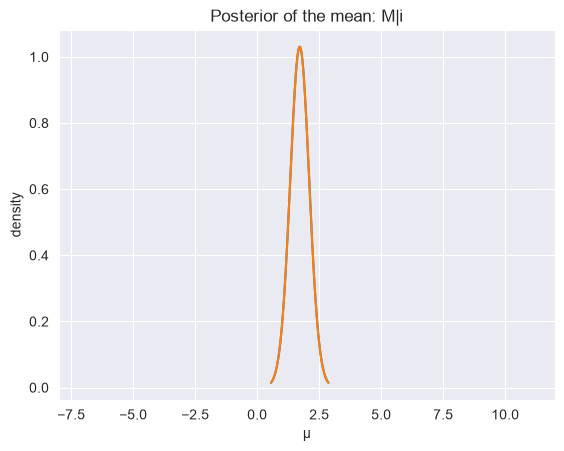

In [10]:
##################### input #####################
# dimension
i_bar = 1
#################################################

# posterior mean parameters
# degrees of freedom
df_pos_m = nu_pos - i_bar + 1

# scale
scale_pos_m = sqrt(nu_pos / (t_pos * (nu_pos - i_bar + 1)) * sigma2_pos)

# pdf
f_pos_m = lambda x: t.pdf(x, df_pos_m, loc=mu_pos, scale=scale_pos_m)

##################### plot #####################
# grid
grid_m = linspace(mu_pos - 3 * scale_pos_m, mu_pos + 3 * scale_pos_m, 200)
# pdf posterior mean
lineplot(x=grid_m, y=f_pos_m(grid_m));
lineplot(x=grid_m, y=f_pos_m(grid_m))
title('Posterior of the mean: M|i')
xlabel('μ')
ylabel('density')
xlim(-8, 12);

Plot 2:

The Posterior variance

This will show the uncertainty about the true variance.

The model puts a wishart distribution on the inverse of the variance.

Flipping it gives an inverse-Wishart on the variance itself.

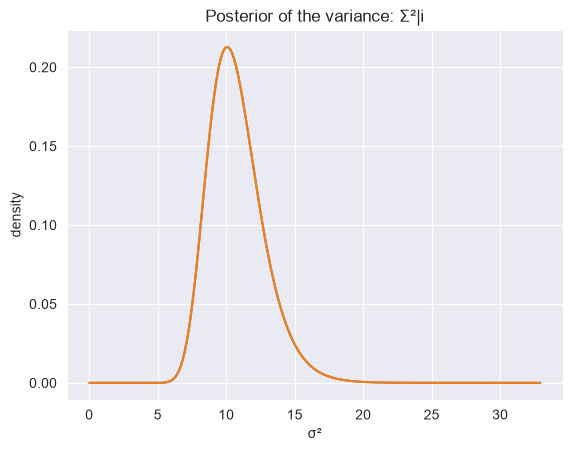

In [11]:
# pdf of posterior variance
f_pos_sigma2 = lambda x: invwishart.pdf(x, df=nu_pos, scale=nu_pos * sigma2_pos)

########################### plot ###########################
grid_s = linspace(0.01, mu_pos + 3*sigma2_pos, 200)  # grid
# pdf of posterior variance
lineplot(x=grid_s, y=f_pos_sigma2(grid_s));
lineplot(x=grid_s, y=f_pos_sigma2(grid_s))
title('Posterior of the variance: Σ²|i')
xlabel('σ²')
ylabel('density');

Plot 3:

The Posterior Predictive future variable Et|i

This is plotting the distribution of tomorrows return, with all the parameter uncertainty folded in.

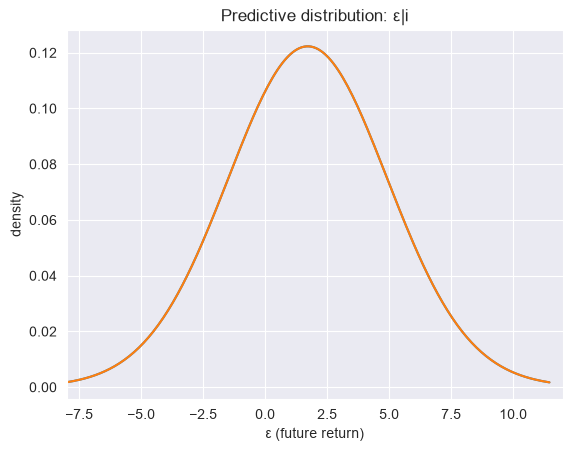

In [12]:
f_pos_pred = lambda x: t.pdf(x, nu_pos, loc=mu_pos, scale=sqrt((t_pos + 1) / t_pos * sigma2_pos))

###################################### plot ######################################
grid_pred = linspace(mu_pos - 3*sqrt((t_pos + 1)/t_pos*sigma2_pos),
                     mu_pos + 3*sqrt((t_pos + 1)/t_pos*sigma2_pos), 200)  # grid
# pdf of posterior predictive future variable
lineplot(x=grid_pred, y=f_pos_pred(grid_pred));
lineplot(x=grid_pred, y=f_pos_pred(grid_pred))
title('Predictive distribution: ε|i')
xlabel('ε (future return)')
ylabel('density')
xlim(-8, 12);

Plot 4:  (Not asked for but, why not...)

Drawing both curves (Plot 1 and Plot 3) on the same chart to show visible difference

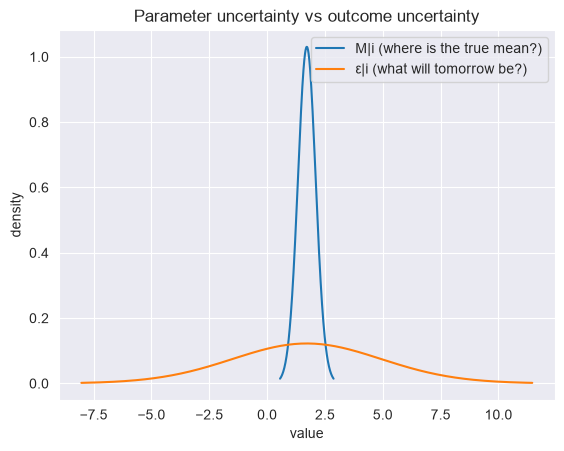

In [13]:
lineplot(x=grid_m, y=f_pos_m(grid_m), label='M|i (where is the true mean?)')
lineplot(x=grid_pred, y=f_pos_pred(grid_pred), label='ε|i (what will tomorrow be?)')
title('Parameter uncertainty vs outcome uncertainty')
xlabel('value')
ylabel('density')
legend();

Where Bayesian estimation shows up in real quant work

1. Short histories. A stock that IPO'd last quarter, a new fund, a strategy you launched two months ago...
2. Expected returns, the hardest thing in finance to estimate.
3. Black-Litterman, the industry's most famous Bayesian model
4. Large covariance matrices.
5. Sequential updating.
6. Risk that includes estimation error.
7. Separating skill from luck.

Limitations to be aware of

1. The prior must be defensible. A bad prior with high confidence drags you to a bad answer.
2. The normal likelihood ignores fat tails. This model assumes normal returns, so crash days get full weight, the opposite of MLFP. Real systems sometimes combine the two ideas.
3. Conjugacy is a convenience, not a truth. NIW is chosen because the maths comes out in closed form. More realistic models need simulation (MCMC) instead of four formulas.

An interview angle

The two estimators you've now built fix two different problems:

MLFP fixes outliers: fat tails distort the estimates.
Bayesian estimation fixes small samples: too little data makes the estimates noisy.

Shrinkage estimators such as James-Stein and Ledoit-Wolf are the Bayesian idea with the confidence level learned from the data. Being able to lay out that map is a strong answer to "how would you estimate a covariance matrix?